# RoadAware · ทุกขั้นตอนในโน้ตบุ๊กเดียว
## จัดการข้อมูล → เชื่อมกับถนน → สร้างตารางเป้าหมายและตัวแปร → เทรนโมเดล → วัดผล

โน้ตบุ๊กนี้รวบรวม **ทุกขั้นตอนของงานไว้ในไฟล์เดียว** และ **รันกับข้อมูลจริงของโปรเจกต์** ทุกตัวเลขที่เห็นคำนวณใหม่ตอนรัน ไม่ได้พิมพ์ใส่เอง

| ส่วน | ทำอะไร | โน้ตบุ๊กต้นฉบับ (โค้ดเต็ม) |
|---|---|---|
| **A** ข้อมูลดิบ | เปิดไฟล์อุบัติเหตุ 5 ปี ดูโครงสร้างและปัญหาของข้อมูล | `01_data_collection` |
| **B** ทำความสะอาด | แปลงวันที่/เวลา ตรวจพิกัด จัดการรหัสซ้ำ | `03_cleaning_preparation`, `14_backend_catalog_national` |
| **C** เชื่อมกับถนน | จับคู่จุดเกิดเหตุกับทางหลวง (ห่างไม่เกิน 50 ม.) และช่วงถนน 2 กม. | `18_spatial_linkage_audit` |
| **D** ตารางเป้าหมาย + ตัวแปร | นับอุบัติเหตุต่อ (ช่วงถนน × วัน × ช่วง 6 ชม.) และสร้าง features | `19_spatial_count_preparation_national` |
| **E** เทรนโมเดล | แบ่งข้อมูลตามเวลา สุ่มแถว 0 เทรน HistGradientBoosting (Poisson) | `20_spatial_count_experiments_national` |
| **F** วัดผล | Poisson deviance, เทียบ baseline, เกณฑ์เลือกโมเดล, สีบนแผนที่, ผลปี 2569 | `20`, `21`, `23` (national) |

**วิธีรัน:** เลือก kernel `.venv` ของโปรเจกต์ แล้วกด **Run All** (ใช้เวลาประมาณ 5–10 นาที ส่วนที่นานที่สุดคือการเทรนและทำนาย 19.7 ล้านแถวในส่วน E–F)

> **ข้อตกลงในการอ่าน**: กล่องสีเทาที่ขึ้นต้นด้วย 💡 คือคำอธิบายว่า "ทำไม" ถึงทำแบบนี้ ซึ่งเป็นสิ่งที่มักถูกถามตอนนำเสนอ

## 0 · เตรียมเครื่องมือ

- `pandas` / `numpy` — จัดการตาราง
- `scikit-learn` — โมเดล `HistGradientBoostingRegressor`
- `matplotlib` — กราฟ

เซลล์ด้านล่างหาโฟลเดอร์โปรเจกต์ให้อัตโนมัติ (ไม่ต้องแก้ path) และตั้งฟอนต์ภาษาไทยให้กราฟ

In [1]:
from pathlib import Path
import json, time, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# หาโฟลเดอร์ RoadAware จากตำแหน่งที่เปิดโน้ตบุ๊ก
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "backend/config/spatial_experiment_v4.json").is_file())
B = REPO / "backend"
RAW = B / "data/raw/accidents"                      # ไฟล์อุบัติเหตุต้นฉบับจาก data.go.th (กระทรวงคมนาคม)
PREP = B / "data/v4/spatial_preparation"            # ผลของโน้ตบุ๊ก 19 (ทั้งประเทศ)
LINK = B / "data/v4/linkage_audit"                  # ผลของโน้ตบุ๊ก 18
RUN20 = B / "rerun-spatial-model-national-20261120-150631/reports/v4/spatial_experiments"   # ผลทางการของโน้ตบุ๊ก 20
RUN21 = B / "rerun-spatial-eval-national-20261120-160533/reports/v4/spatial_evaluation"     # ผลทางการของโน้ตบุ๊ก 21
RUN23 = B / "rerun-2026-eval-national-20261125-084442/reports/v4/evaluation_2026"          # ผลทดสอบปี 2569 (โน้ตบุ๊ก 23)

# ฟอนต์ไทยสำหรับกราฟ (Mac ใช้ Thonburi / Tahoma ได้)
_have = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Thonburi", "Sukhumvit Set", "Tahoma", "Leelawadee UI", "Noto Sans Thai", "Loma"]:
    if name in _have:
        plt.rcParams["font.family"] = name
        break
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

EXP = json.loads((B / "config/spatial_experiment_v4.json").read_text("utf-8"))   # การตั้งค่าการทดลอง (โมเดล, folds, เกณฑ์)
print("โฟลเดอร์โปรเจกต์:", REPO)
print("ไฟล์ดิบที่มี:", sorted(p.name for p in RAW.glob("accidents_*_original.csv")))

โฟลเดอร์โปรเจกต์: /mnt/user-data/uploads/RoadAware
ไฟล์ดิบที่มี: ['accidents_2564_original.csv', 'accidents_2565_original.csv', 'accidents_2566_original.csv', 'accidents_2567_original.csv', 'accidents_2568_original.csv', 'accidents_2569_original.csv']


---
# ส่วน A · ข้อมูลดิบ (Raw data)

แหล่งข้อมูล: **ข้อมูลอุบัติเหตุบนถนน กระทรวงคมนาคม** (datagov.mot.go.th) แยกไฟล์ปีละ 1 ไฟล์

ใช้ฝึกและตรวจโมเดล **ปี พ.ศ. 2564–2568** (ค.ศ. 2021–2025) ส่วนปี 2569 เก็บไว้เป็นชุดทดสอบสุดท้าย (ดูส่วน F7)

In [2]:
YEARS_BE = [2564, 2565, 2566, 2567, 2568]

def read_raw(year_be):
    # อ่านทุกคอลัมน์เป็นข้อความก่อน (dtype=str) เพื่อไม่ให้ pandas เดารูปแบบวันที่/ตัวเลขเอง
    df = pd.read_csv(RAW / f"accidents_{year_be}_original.csv", encoding="utf-8-sig", dtype=str, keep_default_na=False)
    df.columns = [c.strip() for c in df.columns]
    df["be_year"] = year_be
    df["source_row"] = np.arange(2, len(df) + 2)      # เลขแถวในไฟล์ (แถว 1 = หัวตาราง) ใช้ตามรอยกลับไปไฟล์ต้นฉบับ
    return df

raw = {y: read_raw(y) for y in YEARS_BE}
summary = pd.DataFrame([{"ปี พ.ศ.": y, "จำนวนแถว": len(d), "จำนวนคอลัมน์": d.shape[1] - 2,
                         "ขนาดไฟล์ (MB)": round((RAW / f"accidents_{y}_original.csv").stat().st_size / 1e6, 1)} for y, d in raw.items()])
display(summary)
print("รวมทั้งหมด", f"{summary['จำนวนแถว'].sum():,}", "แถว")

รวมทั้งหมด 112,136 แถว


,ปี พ.ศ.,จำนวนแถว,จำนวนคอลัมน์,ขนาดไฟล์ (MB)
0,2564,20062,38,10.4
1,2565,20566,38,10.6
2,2566,23841,38,12.1
3,2567,23952,38,11.3
4,2568,23715,38,12.0


### A1 · คอลัมน์ที่ใช้ในงานนี้

ไฟล์มี 38 คอลัมน์ แต่ขั้นตอนเตรียมข้อมูลของโมเดลใช้แค่บางคอลัมน์:

| คอลัมน์ | ใช้ทำอะไร |
|---|---|
| `ACC_CODE` | รหัสอุบัติเหตุ ใช้ตรวจแถวซ้ำ |
| `วันที่เกิดเหตุ`, `เวลา` | วันและช่วงเวลาที่เกิดเหตุ → นับจำนวนต่อวัน/ต่อช่วง 6 ชม. |
| `LATITUDE`, `LONGITUDE` | ตำแหน่ง → จับคู่กับเส้นทางหลวง |
| `รหัสสายทาง`, `KM`, `จังหวัด` | ใช้ตรวจว่าจับคู่ถนนถูกสาย และตรวจความสมบูรณ์ |

คอลัมน์อื่น (สาเหตุ ลักษณะ สภาพอากาศ ผู้เสียชีวิต) **ไม่ได้ใช้เป็นตัวแปรของโมเดล** เพราะเป็นข้อมูลที่รู้หลังเกิดเหตุแล้ว ใช้แค่ในหน้าแดชบอร์ดและคำอธิบาย "ส่วนใหญ่เกิดจาก" บนเว็บ

In [3]:
display(raw[2566][["ACC_CODE", "วันที่เกิดเหตุ", "เวลา", "รหัสสายทาง", "KM", "จังหวัด", "LATITUDE", "LONGITUDE"]].head(5))

,ACC_CODE,วันที่เกิดเหตุ,เวลา,รหัสสายทาง,KM,จังหวัด,LATITUDE,LONGITUDE
0,7542138,1/1/2023,0:01,รน.4038,0.07,ระนอง,9.958841,98.652833
1,7542110,1/1/2023,0:05,สส.5007,0.7,สมุทรสงคราม,13.455661,100.044082
2,8548373,1/1/2023,0:05,4009,95,สุราษฎร์ธานี,8.568017335,99.11665544
3,7615338,1/1/2023,0:07,2005,5.5,เพชรบูรณ์,16.91159259,101.1916045
4,7536059,1/1/2023,0:10,1112,3,กำแพงเพชร,15.97965797,99.78557912


### A2 · ปัญหาที่เจอในข้อมูลดิบ

แต่ละปีบันทึก **วันที่และเวลาไม่เหมือนกัน** ถ้าอ่านตรง ๆ จะได้วันที่ผิดโดยไม่มี error เตือน เซลล์ด้านล่างแสดงตัวอย่างของแต่ละปี

In [4]:
rows = []
for y, d in raw.items():
    s = d["วันที่เกิดเหตุ"]
    rows.append({"ปี พ.ศ.": y,
                 "ตัวอย่างวันที่": ", ".join(s.iloc[[0, 400, 5000]]),
                 "ตัวอย่างเวลา": ", ".join(d["เวลา"].iloc[[0, 400, 5000]]),
                 "วันที่เป็นตัวเลข Excel": int(s.str.fullmatch(r"\d+").sum()),
                 "วันที่มี /": int(s.str.contains("/").sum()),
                 "เวลาเป็นเศษส่วนของวัน": int(d["เวลา"].str.fullmatch(r"0?\.\d+").sum())})
display(pd.DataFrame(rows))

,ปี พ.ศ.,ตัวอย่างวันที่,ตัวอย่างเวลา,วันที่เป็นตัวเลข Excel,วันที่มี /,เวลาเป็นเศษส่วนของวัน
0,2564,"1/1/2021, 1/2/2021, 3/19/2021","0:00, 14:30, 19:00",0,20062,0
1,2565,"01/01/2022, 02/01/2022, 03/26/2022","0:01, 12:30, 17:44",0,20566,0
2,2566,"1/1/2023, 1/2/2023, 3/16/2023","0:01, 12:20, 21:00",0,23841,0
3,2567,"45292, 45293, 45359","0.008333333, 0.645833333, 0.885416667",23952,0,23912
4,2568,"45658, 45659, 45727","0:00, 20:30, 0:40",23715,0,0


อ่านจากตารางได้ว่า:

- **2564–2566** ส่วนใหญ่เขียน `เดือน/วัน/ปี` (เช่น `1/2/2023` = 2 ม.ค.) แต่ **ปี 2565 มีบางช่วงเขียนสลับเป็น `วัน/เดือน/ปี`** (เช่น `12/04/2022` ในช่วงสงกรานต์ = 12 เม.ย.)
- **2567, 2568** วันที่เป็น **เลขลำดับวันของ Excel** (เช่น `45292` = 1 ม.ค. 2024)
- **2567** เวลาเป็น **เศษส่วนของวัน** (เช่น `0.5` = 12:00)

> 💡 **ทำไมต้องระวัง:** `1/2/2023` อ่านได้ทั้ง 1 ก.พ. และ 2 ม.ค. ถ้าเดาผิด อุบัติเหตุจะไปอยู่ผิดวัน ข้อมูลเทศกาลและฤดูกาลก็จะผิดทั้งหมด เราจึง **เลือกจากหลักฐานในไฟล์** แทนการเดา

---
# ส่วน B · ทำความสะอาดข้อมูล (Cleaning)

กติกาทั้งหมดมาจากโน้ตบุ๊ก `03_cleaning_preparation` (cell 2: `parse_date`, `parse_time`, `coord_status`, `assign_dispositions`) และ `14_backend_catalog_national`

ด้านล่างเขียนใหม่ให้สั้นและอ่านง่ายขึ้น แต่ใช้กติกาเดียวกัน

### B1 · แปลงวันที่

ขั้นตอนของฟังก์ชัน `parse_dates`:
1. ถ้าเป็นตัวเลข Excel ให้นับวันต่อจาก 30 ธ.ค. 1899 (จุดเริ่มต้นของ Excel)
2. ถ้าเป็น `a/b/ปี` ให้ลองอ่านทั้ง เดือน/วัน และ วัน/เดือน (ถ้าปี > 2400 แปลว่าเป็น พ.ศ. ให้ลบ 543)
   - อ่านได้แบบเดียว (เช่น `01/13/2022` มีเดือน 13 ไม่ได้) → ใช้แบบนั้น
   - อ่านได้ 2 แบบ (เช่น `02/01/2022`) → ไฟล์เรียงตามวันที่ จึงเลือกแบบที่ใกล้กับแถวข้างเคียงที่อ่านได้ชัดเจน
   - (pipeline จริงตัดสินแถวกำกวมด้วย **ไฟล์ XLSX ต้นฉบับของกระทรวง** ในโน้ตบุ๊ก 09–10 วิธีในโน้ตบุ๊กนี้ง่ายกว่า แต่ได้วันที่ตรงกัน 100% ตรวจได้ในส่วน B5)
3. วันที่ที่ไม่ตรงกับปีของไฟล์ถือว่าผิด

In [5]:
EXCEL_ORIGIN = pd.Timestamp("1899-12-30")

def parse_dates(s, year_ce):
    # คืนค่า (วันที่, วิธีที่ใช้อ่าน) ของทุกแถว
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    how = pd.Series("อ่านไม่ได้", index=s.index, dtype=object)

    # 1) ตัวเลข Excel: นับวันต่อจาก 30 ธ.ค. 1899
    serial = s.str.fullmatch(r"\d+(\.0+)?")
    n = pd.to_numeric(s.where(serial), errors="coerce")
    ok = serial & n.between(30000, 60000)
    out[ok] = EXCEL_ORIGIN + pd.to_timedelta(n[ok], unit="D")
    how[ok] = "Excel serial"

    # 2) แบบ a/b/ปี: อ่านได้ 2 แบบ คือ เดือน/วัน (MDY) และ วัน/เดือน (DMY)
    slash = s.str.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}")
    p = s.where(slash).str.split("/", expand=True)
    if slash.any():
        a, b, y = (pd.to_numeric(p[i], errors="coerce") for i in range(3))
        y = y.where(y < 2400, y - 543)                                  # ปี พ.ศ. → ค.ศ.
        mdy = pd.to_datetime(dict(year=y, month=a, day=b), errors="coerce")
        dmy = pd.to_datetime(dict(year=y, month=b, day=a), errors="coerce")
        only_mdy = slash & mdy.notna() & (dmy.isna() | (mdy == dmy))    # อ่านได้แบบเดียว (หรือสองแบบได้วันเดียวกัน)
        only_dmy = slash & dmy.notna() & mdy.isna()
        out[only_mdy], how[only_mdy] = mdy[only_mdy], "a/b/ปี อ่านได้แบบเดียว"
        out[only_dmy], how[only_dmy] = dmy[only_dmy], "a/b/ปี อ่านได้แบบเดียว"
        # 3) อ่านได้ 2 แบบและได้วันต่างกัน เช่น 02/01/2022: ไฟล์เรียงตามวันที่ จึงเลือกแบบที่ใกล้วันของแถวข้างเคียงที่ชัดเจน
        both = slash & mdy.notna() & dmy.notna() & (mdy != dmy)
        ref = out.where(~both).ffill().bfill()
        pick_dmy = (dmy - ref).abs() < (mdy - ref).abs()
        out[both] = np.where(pick_dmy[both], dmy[both], mdy[both])
        how[both] = "a/b/ปี กำกวม → เลือกตามแถวข้างเคียง"
    bad = out.notna() & (out.dt.year != year_ce)                        # ปีต้องตรงกับไฟล์
    out[bad], how[bad] = pd.NaT, "ปีไม่ตรงกับไฟล์"
    return out, how

how_all = []
for y, d in raw.items():
    d["event_date"], d["date_how"] = parse_dates(d["วันที่เกิดเหตุ"], y - 543)
    how_all.append(d["date_how"].value_counts().rename(y))
display(pd.concat(how_all, axis=1).fillna(0).astype(int))
print("ตัวอย่างแถวที่กำกวมของปี 2565:")
x = raw[2565]
display(x.loc[x["date_how"].str.startswith("a/b/ปี กำกวม"), ["source_row", "วันที่เกิดเหตุ", "event_date"]].iloc[[0, 1, 200, 2000]])

ตัวอย่างแถวที่กำกวมของปี 2565:


,2564,2565,2566,2567,2568
date_how,,,,,
a/b/ปี อ่านได้แบบเดียว,12649,13298,15546,0,0
a/b/ปี กำกวม → เลือกตามแถวข้างเคียง,7413,7268,8295,0,0
Excel serial,0,0,0,23952,23715


,source_row,วันที่เกิดเหตุ,event_date
310,312,02/01/2022,2022-01-02
311,313,02/01/2022,2022-01-02
510,512,02/01/2022,2022-01-02
4219,4221,11/03/2022,2022-03-11


### B2 · แปลงเวลา และจัดเข้าช่วง 6 ชั่วโมง

โมเดลทำนายเป็น **4 ช่วงต่อวัน**: `00-06`, `06-12`, `12-18`, `18-24` เวลาแต่ละรายการจึงต้องแปลงเป็นช่วงเหล่านี้

- `H:MM` หรือ `H:MM:SS` อ่านตรง ๆ
- ตัวเลข 0–1 (เช่น `0.008333`) คือเศษส่วนของ 1 วัน คูณ 86,400 เป็นวินาที
- ถ้าปัดแล้วกลายเป็น 24:00 ถือว่าผิด เพราะจะทำให้วันที่เลื่อนไปอีกวันโดยไม่ตั้งใจ

In [6]:
BLOCKS = ["00-06", "06-12", "12-18", "18-24"]

def parse_seconds(s):
    sec = pd.Series(np.nan, index=s.index)
    hm = s.str.extract(r"^(\d{1,2}):(\d{2})(?::(\d{2}))?$").astype(float)
    ok = hm[0].lt(24) & hm[1].lt(60) & hm[2].fillna(0).lt(60)
    sec[ok] = hm[0][ok] * 3600 + hm[1][ok] * 60 + hm[2].fillna(0)[ok]
    frac = pd.to_numeric(s.where(~ok), errors="coerce")
    fok = frac.ge(0) & frac.lt(1) & (np.round(frac * 86400) < 86400)
    sec[fok] = np.round(frac[fok] * 86400)
    return sec

for y, d in raw.items():
    d["seconds"] = parse_seconds(d["เวลา"])
    d["time_block"] = pd.cut(d["seconds"], [0, 21600, 43200, 64800, 86400], right=False, labels=BLOCKS).astype(object)
    print(y, "เวลาอ่านไม่ได้:", int(d["seconds"].isna().sum()), "แถว")

print("\nตัวอย่างปี 2567 (เวลาเป็นเศษส่วน):")
display(raw[2567][["เวลา", "seconds", "time_block"]].head(4))

2564 เวลาอ่านไม่ได้: 0 แถว
2565 เวลาอ่านไม่ได้: 0 แถว
2566 เวลาอ่านไม่ได้: 0 แถว
2567 เวลาอ่านไม่ได้: 0 แถว
2568 เวลาอ่านไม่ได้: 0 แถว

ตัวอย่างปี 2567 (เวลาเป็นเศษส่วน):


,เวลา,seconds,time_block
0,0.008333333,720.0,00-06
1,0.020833333,1800.0,00-06
2,0.020833333,1800.0,00-06
3,0.020833333,1800.0,00-06


### B3 · ตรวจพิกัด

- พิกัดว่าง หรืออยู่นอกกรอบประเทศไทย (ละติจูด 5–21°, ลองจิจูด 97–106°) **ใช้จับคู่กับถนนไม่ได้**
- ถ้าเดาพิกัดให้ จุดจะไปลงถนนผิดเส้น เราจึงไม่ซ่อมพิกัด แค่ติดป้ายเหตุผลว่าทำไมไม่ได้ใช้

In [7]:
for y, d in raw.items():
    lat = pd.to_numeric(d["LATITUDE"], errors="coerce")
    lon = pd.to_numeric(d["LONGITUDE"], errors="coerce")
    d["lat"], d["lon"] = lat, lon
    d["coord_ok"] = lat.between(5, 21) & lon.between(97, 106)
    print(y, "พิกัดใช้ไม่ได้:", int((~d["coord_ok"]).sum()), "แถว")

2564 พิกัดใช้ไม่ได้: 65 แถว
2565 พิกัดใช้ไม่ได้: 73 แถว
2566 พิกัดใช้ไม่ได้: 180 แถว
2567 พิกัดใช้ไม่ได้: 238 แถว
2568 พิกัดใช้ไม่ได้: 171 แถว


### B4 · รหัสอุบัติเหตุซ้ำ (`ACC_CODE`)

ถ้ามีหลายแถวใช้ `ACC_CODE` เดียวกัน (พบในปี 2566):
- ทุกแถวข้อมูลเหมือนกันหมด → **เก็บแถวแรก** (นับเป็นเหตุเดียว)
- ข้อมูลขัดกัน (มีช่องใดช่องหนึ่งไม่ตรงกัน) → **กันออกทั้งกลุ่ม (quarantine)** เพราะไม่รู้ว่าแถวไหนถูก

ในข้อมูลจริง **ทุกกลุ่มที่ซ้ำมีบางช่องไม่ตรงกัน** (เช่น บริเวณที่เกิดเหตุ ลักษณะการเกิดเหตุ หรือวันที่) จึงถูกกันออกทั้งหมด

> 💡 ถ้านับซ้ำ จุดนั้นจะดูอันตรายเกินจริง และถ้าเลือกเก็บแถวใดแถวหนึ่งเอง ก็คือการเดา

In [8]:
for y, d in raw.items():
    KEY = list(d.columns[:list(d.columns).index("be_year")])                    # เทียบทุกช่องของไฟล์ต้นฉบับ
    code_ = d["ACC_CODE"].str.strip()
    grp = d.groupby(code_)
    size = grp["source_row"].transform("size")
    n_versions = d[KEY].astype(str).agg("|".join, axis=1).groupby(code_).transform("nunique")
    first = grp["source_row"].transform("min")
    d["dup_status"] = np.select([size == 1, n_versions == 1], ["unique", "identical_copy"], "conflict")
    d["dup_keep"] = (d["dup_status"] == "unique") | ((d["dup_status"] == "identical_copy") & (d["source_row"] == first))
    if (size > 1).any():
        print(y, "แถวที่รหัสซ้ำ:", int((size > 1).sum()), "| รหัสที่ซ้ำ:", int(code_[size > 1].nunique()),
              "| ข้อมูลขัดกัน (กันออกทั้งกลุ่ม):", int((d["dup_status"] == "conflict").sum()))

2566 แถวที่รหัสซ้ำ: 3343 | รหัสที่ซ้ำ: 1641 | ข้อมูลขัดกัน (กันออกทั้งกลุ่ม): 3343


### B5 · จังหวัดว่าง และสรุปผลการทำความสะอาด

ปี 2567 มีประมาณ 1,900 แถวที่ช่อง `จังหวัด` ว่าง จึงตรวจความสอดคล้องของตำแหน่งกับจังหวัดไม่ได้ แถวเหล่านี้ถูกกันออก (`province_missing` ในโน้ตบุ๊ก 03 `row_reasons`)

ตารางด้านล่างคือ **funnel** ว่าข้อมูลหายไปตรงไหนและด้วยเหตุผลอะไร แถวหนึ่งอาจมีปัญหาหลายอย่าง จึงนับเฉพาะเหตุผลแรกที่เจอ

In [9]:
funnel = []
clean_parts = []
for y, d in raw.items():
    reason = np.select(
        [d["event_date"].isna(), d["seconds"].isna(), ~d["coord_ok"], d["จังหวัด"].str.strip() == "", ~d["dup_keep"]],
        ["วันที่ผิด", "เวลาผิด", "พิกัดใช้ไม่ได้", "ไม่มีจังหวัด", "รหัสซ้ำ/ขัดกัน"], default="ผ่าน")
    d["clean_reason"] = reason
    funnel.append(pd.Series(reason).value_counts().rename(y))
    clean_parts.append(d[reason == "ผ่าน"])
funnel = pd.concat(funnel, axis=1).fillna(0).astype(int)
funnel["รวม"] = funnel.sum(axis=1)
display(funnel)

clean = pd.concat(clean_parts, ignore_index=True)
print(f"ข้อมูลดิบ {sum(len(d) for d in raw.values()):,} แถว → ผ่านการทำความสะอาด {len(clean):,} แถว")

ข้อมูลดิบ 112,136 แถว → ผ่านการทำความสะอาด 106,308 แถว


,2564,2565,2566,2567,2568,รวม
ผ่าน,19996,20492,20490,21788,23542,106308
พิกัดใช้ไม่ได้,65,73,180,238,171,727
ไม่มีจังหวัด,1,1,8,1926,2,1938
รหัสซ้ำ/ขัดกัน,0,0,3163,0,0,3163


**เทียบกับผลของ pipeline จริง:** โน้ตบุ๊ก 18 รับข้อมูลที่สะอาดแล้วเข้าไปจับคู่กับถนน (`event_linkage_audit.csv.gz`) ถ้ากติกาด้านบนตรงกับของจริง ชุดแถวที่ผ่านต้องตรงกันเกือบทั้งหมด

In [10]:
audit = pd.read_csv(LINK / "event_linkage_audit.csv.gz", low_memory=False,
                    usecols=["event_uid", "be_year", "source_row", "event_date", "time_block", "status_50m", "segment_status",
                             "chosen_distance_m", "first_matched_tolerance_m", "source_id", "segment_id_2000m", "province_key"])
ours = set(zip(clean["be_year"], clean["source_row"]))
theirs = set(zip(audit["be_year"], audit["source_row"]))
print(f"pipeline จริง: {len(theirs):,} แถว | ของเรา: {len(ours):,} แถว | ตรงกัน: {len(ours & theirs):,} แถว "
      f"({len(ours & theirs) / len(theirs):.2%} ของ pipeline จริง)")

# วันที่และช่วงเวลาที่เราแปลงได้ ตรงกับของจริงไหม
m = clean.merge(audit, on=["be_year", "source_row"], suffixes=("", "_ref"))
same_date = (m["event_date"].dt.strftime("%Y-%m-%d") == m["event_date_ref"]).mean()
same_block = (m["time_block"] == m["time_block_ref"]).mean()
print(f"วันที่ตรงกัน {same_date:.2%} | ช่วง 6 ชม. ตรงกัน {same_block:.2%}")

pipeline จริง: 106,308 แถว | ของเรา: 106,308 แถว | ตรงกัน: 106,308 แถว (100.00% ของ pipeline จริง)
วันที่ตรงกัน 100.00% | ช่วง 6 ชม. ตรงกัน 100.00%


### B6 · ดูข้อมูลหลังทำความสะอาด (EDA สั้น ๆ)

ก่อนสร้างโมเดล ต้องรู้ว่าอุบัติเหตุกระจายตัวตามเวลาอย่างไร ตัวแปรเรื่องเวลาที่ใส่ในส่วน D มาจากสิ่งที่เห็นตรงนี้

เฉลี่ยต่อวัน: วันปกติ 52.9 | สงกรานต์ 191.6 | ปีใหม่ 193.9 ครั้ง/วัน


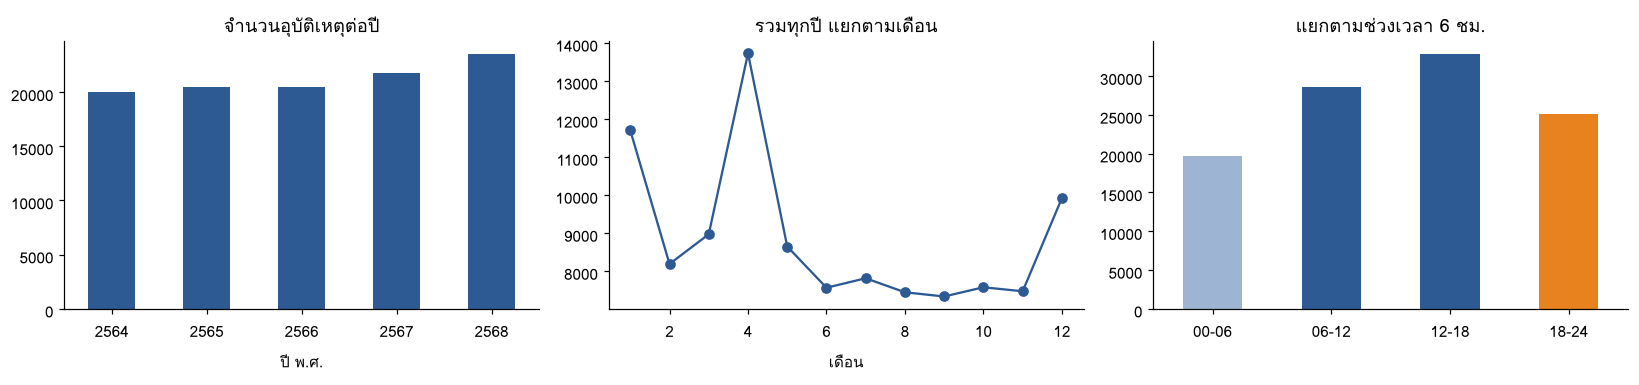

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
c = clean.copy()
c["month"] = c["event_date"].dt.month
c["block"] = c["time_block"]
c.groupby("be_year").size().plot.bar(ax=ax[0], color="#2D5A93")
ax[0].set_title("จำนวนอุบัติเหตุต่อปี"); ax[0].set_xlabel("ปี พ.ศ.")
c.groupby("month").size().plot(ax=ax[1], marker="o", color="#2D5A93")
ax[1].set_title("รวมทุกปี แยกตามเดือน"); ax[1].set_xlabel("เดือน")
c.groupby("block").size().reindex(BLOCKS).plot.bar(ax=ax[2], color=["#9DB4D3", "#2D5A93", "#2D5A93", "#E8821E"])
ax[2].set_title("แยกตามช่วงเวลา 6 ชม."); ax[2].set_xlabel("")
for a in ax: a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

# วันเทศกาลมีอุบัติเหตุต่อวันมากกว่าวันปกติแค่ไหน
d = c["event_date"]
songkran = (d.dt.month == 4) & d.dt.day.between(11, 17)
newyear = ((d.dt.month == 12) & (d.dt.day >= 29)) | ((d.dt.month == 1) & (d.dt.day <= 4))
days = pd.Series(1, index=pd.date_range("2021-01-01", "2025-12-31"))
dd = days.index
n_song = ((dd.month == 4) & (dd.day >= 11) & (dd.day <= 17)).sum()
n_ny = (((dd.month == 12) & (dd.day >= 29)) | ((dd.month == 1) & (dd.day <= 4))).sum()
print(f"เฉลี่ยต่อวัน: วันปกติ {(~songkran & ~newyear).sum() / (len(dd) - n_song - n_ny):.1f} | "
      f"สงกรานต์ {songkran.sum() / n_song:.1f} | ปีใหม่ {newyear.sum() / n_ny:.1f} ครั้ง/วัน")

---
# ส่วน C · เชื่อมอุบัติเหตุกับถนน (Spatial linkage)

โมเดลทำนาย **ราย "ช่วงถนน"** ไม่ใช่รายจุด จึงต้องรู้ว่าอุบัติเหตุแต่ละครั้งเกิดบนช่วงถนนไหน

### C1 · ถนนที่ใช้ (universe)

- ใช้เส้นทางหลวงของ **กรมทางหลวง** จาก Transport GIS (กระทรวงคมนาคม) มาตัดเป็น **ช่วงละ 2 กม.**
- เก็บเฉพาะทางหลวงสายมาตรฐานที่ยาวอย่างน้อย 500 ม.
- **ชุดถนนนี้กำหนดจากรูปร่างถนนอย่างเดียว ก่อนดูผลโมเดลใด ๆ** และรวมช่วงที่ไม่เคยเกิดเหตุด้วย

> 💡 ถ้าเลือกเฉพาะถนนที่เคยเกิดเหตุ โมเดลจะไม่เคยเห็นถนนที่ปลอดภัยเลย และจะทายสูงเกินจริงทุกที่

ช่วงถนน 26,740 ช่วง | ทางหลวง 1,440 สาย | ยาวรวม 51,858 กม.


,segment_id,route_code,geom_mid_lat,geom_mid_lon,geom_length_m,geom_straightness,geom_turning_rad_per_km
0,rsv1-rc315c7c508f:doh:1000:p0:c0:r2000:00000,3420,15.468724,100.541460,2000.0,0.999935,0.475720
1,rsv1-rc315c7c508f:doh:1000:p0:c0:r2000:00001,3420,15.462690,100.559028,2000.0,0.999981,0.372683
2,rsv1-rc315c7c508f:doh:1001:p0:c0:r2000:00000,1087,17.769248,98.949274,2000.0,0.950149,1.917787


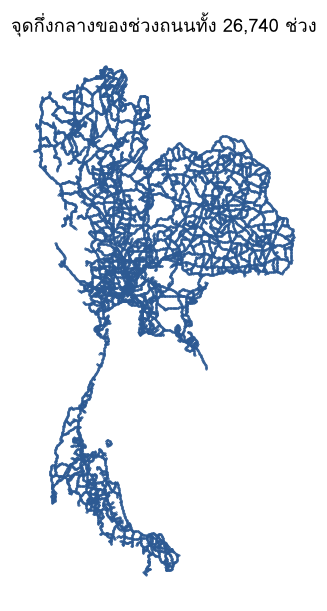

In [12]:
uni = pd.read_csv(PREP / "universe_segments.csv", dtype={"route_code": str})
print(f"ช่วงถนน {len(uni):,} ช่วง | ทางหลวง {uni['route_code'].nunique():,} สาย | ยาวรวม {uni['geom_length_m'].sum() / 1000:,.0f} กม.")
display(uni[["segment_id", "route_code", "geom_mid_lat", "geom_mid_lon", "geom_length_m", "geom_straightness", "geom_turning_rad_per_km"]].head(3))

fig, ax = plt.subplots(figsize=(4.2, 6.6))
ax.scatter(uni["geom_mid_lon"], uni["geom_mid_lat"], s=0.15, c="#2D5A93")
ax.set_aspect(1.03); ax.set_title("จุดกึ่งกลางของช่วงถนนทั้ง 26,740 ช่วง"); ax.axis("off")
plt.show()

### C2 · จับคู่จุดเกิดเหตุกับเส้นทาง (โน้ตบุ๊ก 18)

แต่ละรายการถูกจับคู่กับเส้นทางที่ใกล้ที่สุดซึ่ง **เลขสายทางตรงกับที่บันทึกไว้** แล้วติดสถานะ:

| สถานะ (`status_50m`) | ความหมาย |
|---|---|
| `matched` | ห่างจากถนนไม่เกิน 50 ม. และไม่มีถนนอื่นแย่งในระยะใกล้เคียง |
| `too_far` | ใกล้ที่สุดก็ยังเกิน 50 ม. |
| `ambiguous_*` | มีถนนหลายเส้นใกล้พอ ๆ กัน ไม่รู้ว่าเกิดบนเส้นไหน |
| `identity_unresolved` / `route_*` | เลขสายทางไม่ตรงหรือไม่มีในข้อมูลถนน |

> 💡 **ทำไม 50 ม.:** โน้ตบุ๊ก 18 ลองทั้ง 25, 50 และ 100 ม. ระยะ 50 ม. เผื่อความคลาดเคลื่อนของ GPS ได้ โดยยังไม่ไปจับคู่ผิดกับถนนข้างเคียง

**รัน linkage ใหม่ในนี้ไม่ได้** เพราะต้องใช้ไฟล์เส้นถนนขนาด 233 MB และไลบรารี shapely ด้านล่างจึงอ่านผลจริงของโน้ตบุ๊ก 18 มาแสดง

ระยะกลาง (median) 1.1 ม. | 90% อยู่ใน 16.0 ม.


,จำนวน,สัดส่วน
status_50m,,
matched,101739,95.7%
too_far,1673,1.6%
identity_unresolved,1080,1.0%
ambiguous_unsafe_geometry,777,0.7%
route_special_unverified,548,0.5%
ambiguous_multiple,385,0.4%
route_not_in_snapshot,61,0.1%
low_precision_unsuitable,36,0.0%
route_missing,9,0.0%


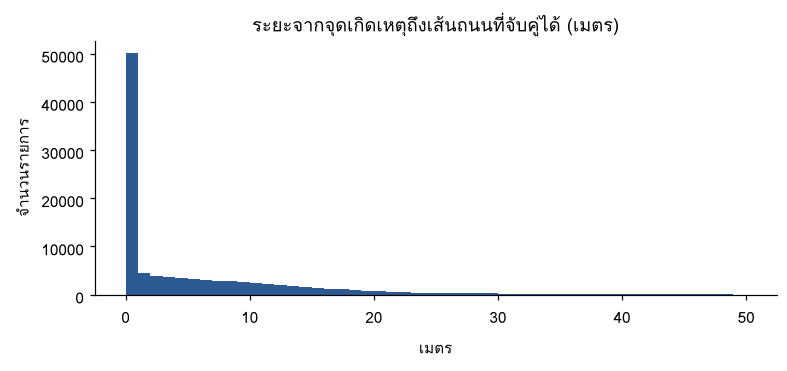

In [13]:
st = audit["status_50m"].value_counts().rename("จำนวน").to_frame()
st["สัดส่วน"] = (st["จำนวน"] / len(audit)).map("{:.1%}".format)
display(st)

dist = audit.loc[audit["status_50m"] == "matched", "chosen_distance_m"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(dist.clip(upper=50), bins=50, color="#2D5A93")
ax.set_title("ระยะจากจุดเกิดเหตุถึงเส้นถนนที่จับคู่ได้ (เมตร)"); ax.set_xlabel("เมตร"); ax.set_ylabel("จำนวนรายการ")
plt.show()
print(f"ระยะกลาง (median) {dist.median():.1f} ม. | 90% อยู่ใน {dist.quantile(.9):.1f} ม.")

### C3 · เลือกรายการที่ใช้ฝึกโมเดล (`select_events` · โน้ตบุ๊ก 19 cell 4)

เงื่อนไขที่ต้องผ่านทุกข้อ:
1. `status_50m == "matched"` (จับคู่ได้ภายใน 50 ม.)
2. ได้ช่วงถนน 2 กม. (`segment_status == "assigned"`)
3. ช่วงถนนนั้นอยู่ในชุดถนน 26,740 ช่วง (ไม่ใช่ถนนกรมทางหลวงชนบท ทางพิเศษ หรือช่วงสั้นกว่า 500 ม.)

รายการที่ไม่ผ่าน **ไม่ถูกนับเป็นศูนย์** แต่เก็บป้ายเหตุผลไว้ (`unknown_scope_events.csv.gz`)

In [14]:
sel = pd.read_csv(PREP / "selected_events.csv.gz")
unk = pd.read_csv(PREP / "unknown_scope_events.csv.gz")
in_universe = set(uni["segment_id"])
ok = (audit["status_50m"] == "matched") & (audit["segment_status"] == "assigned") & audit["segment_id_2000m"].isin(in_universe)
print(f"ผ่านการทำความสะอาด {len(audit):,} → จับคู่ได้ใน 50 ม. {int((audit['status_50m'] == 'matched').sum()):,} → อยู่ในชุดถนน {int(ok.sum()):,} รายการ")
print(f"ไฟล์ selected_events ของโน้ตบุ๊ก 19 มี {len(sel):,} รายการ → ตรงกัน: {set(audit.loc[ok, 'event_uid']) == set(sel['event_uid'])}")
display(unk["selection"].value_counts().rename("รายการที่ไม่ได้ใช้ (เหตุผล)").to_frame())

ผ่านการทำความสะอาด 106,308 → จับคู่ได้ใน 50 ม. 101,739 → อยู่ในชุดถนน 98,207 รายการ
ไฟล์ selected_events ของโน้ตบุ๊ก 19 มี 98,207 รายการ → ตรงกัน: True


,รายการที่ไม่ได้ใช้ (เหตุผล)
selection,
unsupported_segment_unsupported_source_drr_rural,3100
unknown_status_50m_too_far,1673
unknown_status_50m_identity_unresolved,1080
unknown_status_50m_ambiguous_unsafe_geometry,777
unknown_status_50m_route_special_unverified,548
unsupported_segment_short_lt_min_length,432
unknown_status_50m_ambiguous_multiple,385
unknown_status_50m_route_not_in_snapshot,61
unknown_status_50m_low_precision_unsuitable,36


---
# ส่วน D · ตารางเป้าหมาย (label) และตัวแปร (features)

### D1 · สิ่งที่โมเดลทำนาย

> **y = จำนวนอุบัติเหตุที่ถูกบันทึกและจับคู่ได้ บนช่วงถนน *s* ในวัน *d* ช่วงเวลา *b***

1 แถวของข้อมูล = 1 ช่วงถนน × 1 วัน × 1 ช่วง 6 ชม. ทุกช่วงถนน ทุกวัน ทุกช่วงเวลา **รวมช่องที่ไม่มีเหตุ (y = 0)** จึงมีจำนวนช่องมหาศาล

In [15]:
c6 = pd.read_csv(PREP / "counts_6h.csv.gz")                      # เก็บเฉพาะช่องที่ y > 0 (sparse) ช่องที่ไม่อยู่ในไฟล์ = 0
n_days = (pd.Timestamp("2025-12-31") - pd.Timestamp("2021-01-01")).days + 1
cells = len(uni) * n_days * 4
print(f"ช่องทั้งหมด = {len(uni):,} ช่วงถนน × {n_days:,} วัน × 4 ช่วง = {cells:,} ช่อง")
print(f"ช่องที่เกิดเหตุ (y ≥ 1) = {len(c6):,} ช่อง → เป็นศูนย์ {1 - len(c6) / cells:.4%}")
display(c6["y_count"].value_counts().sort_index().rename("จำนวนช่อง").to_frame().T)

# ตรวจว่านับจาก selected_events แล้วได้ตารางเดียวกับไฟล์จริง
recount = sel.groupby(["segment_id_2000m", "event_date", "time_block"]).size().rename("y").reset_index()
chk = recount.merge(c6, left_on=["segment_id_2000m", "event_date", "time_block"], right_on=["segment_id", "target_date", "time_block"], how="outer")
print("นับใหม่ได้ตรงกับ counts_6h.csv.gz ทุกช่อง:", bool((chk["y"] == chk["y_count"]).all()))

ช่องทั้งหมด = 26,740 ช่วงถนน × 1,826 วัน × 4 ช่วง = 195,308,960 ช่อง
ช่องที่เกิดเหตุ (y ≥ 1) = 96,765 ช่อง → เป็นศูนย์ 99.9505%
นับใหม่ได้ตรงกับ counts_6h.csv.gz ทุกช่อง: True


y_count,1,2,3,4,6
จำนวนช่อง,95416,1271,69,6,3


> 💡 **ข้อมูลแทบทั้งหมดเป็น 0 (มากกว่า 99.9%)** จึงใช้ accuracy หรือ RMSE วัดผลไม่ได้ เพราะทาย 0 ทุกช่องก็ดูแม่นแล้ว เราจึงใช้ **Poisson** ทั้งตอนฝึก (loss) และตอนวัดผล (deviance) ซึ่งออกแบบมาสำหรับ "จำนวนนับของเหตุการณ์ที่เกิดไม่บ่อย"

### D2 · ตัวแปรของถนน (static features · โน้ตบุ๊ก 19 cell 3 `STATIC_FEATURES`)

| ตัวแปร | ความหมาย |
|---|---|
| `route_code` | เลขทางหลวง (categorical) เช่น 1, 2, 32 |
| `geom_mid_x_m`, `geom_mid_y_m`, `geom_mid_lon`, `geom_mid_lat` | ตำแหน่งกึ่งกลางช่วงถนน |
| `geom_length_m`, `geom_log_length_m` | ความยาวช่วง (ช่วงยาวกว่ามีโอกาสเกิดเหตุมากกว่า) |
| `geom_bearing_sin`, `geom_bearing_cos` | ทิศทางของถนน |
| `geom_straightness` | ความตรง (1 = ตรงมาก) |
| `geom_turning_rad_per_km` | ความโค้งต่อ กม. (ถนนคดเคี้ยว) |

In [16]:
STATIC = ["route_code", "geom_mid_x_m", "geom_mid_y_m", "geom_mid_lon", "geom_mid_lat", "geom_length_m", "geom_log_length_m",
          "geom_bearing_sin", "geom_bearing_cos", "geom_straightness", "geom_turning_rad_per_km"]
display(uni[STATIC].describe().T[["mean", "min", "50%", "max"]].round(3))

,mean,min,50%,max
geom_mid_x_m,724445.031,367890.694,683565.572,1203349.036
geom_mid_y_m,1639501.431,627455.414,1704190.379,2260858.342
geom_mid_lon,101.091,97.752,100.704,105.545
geom_mid_lat,14.812,5.673,15.383,20.444
geom_length_m,1939.334,500.000,2000.000,2000.000
geom_log_length_m,7.557,6.215,7.601,7.601
geom_bearing_sin,0.121,-1.000,0.188,1.000
geom_bearing_cos,0.094,-1.000,0.154,1.000
geom_straightness,0.947,0.135,0.985,1.000
geom_turning_rad_per_km,1.875,0.000,1.085,60.539


### D3 · ตัวแปรของวัน (calendar features · `date_features.csv`)

| กลุ่ม | ตัวแปร |
|---|---|
| วันในสัปดาห์ / เดือน | `day_of_week`, `month`, `day_of_month`, `is_weekend` |
| ฤดูกาลแบบวงกลม | `doy_sin`, `doy_cos` (31 ธ.ค. กับ 1 ม.ค. อยู่ติดกัน) |
| เทศกาล | สงกรานต์ / ปีใหม่: อยู่ในเทศกาล (`_in`), ก่อน 1–3 วัน, 4–7 วัน, หลัง 1–3 วัน, 4–7 วัน และระยะห่างจากเทศกาล (`_dist`) |
| ฤดู | ร้อน (มี.ค.–พ.ค.), ฝน (มิ.ย.–ต.ค.), หนาว (พ.ย.–ก.พ.) |
| วันหยุดธนาคาร | `bank_holiday_asof` ใช้เฉพาะปฏิทินที่ประกาศแล้ว ณ วันที่ทำนาย |

ตัวอย่างช่วงสงกรานต์ 2566 (2023):

In [17]:
CTX = json.loads((PREP / "context_settings.json").read_text("utf-8"))
DATE_COLS = CTX["date_feature_columns"]
dates = pd.read_csv(PREP / "date_features.csv")
display(dates.loc[dates["target_date"].between("2023-04-07", "2023-04-19"),
                  ["target_date", "day_of_week", "fest_songkran_dist", "fest_songkran_pre_1_3", "fest_songkran_in", "fest_songkran_post_1_3", "season_hot", "bank_holiday_asof"]])

,target_date,day_of_week,fest_songkran_dist,fest_songkran_pre_1_3,fest_songkran_in,fest_songkran_post_1_3,season_hot,bank_holiday_asof
826,2023-04-07,4.0,-6.0,0.0,0.0,0.0,1.0,0.0
827,2023-04-08,5.0,-5.0,0.0,0.0,0.0,1.0,0.0
828,2023-04-09,6.0,-4.0,0.0,0.0,0.0,1.0,0.0
829,2023-04-10,0.0,-3.0,1.0,0.0,0.0,1.0,0.0
830,2023-04-11,1.0,-2.0,1.0,0.0,0.0,1.0,0.0
831,2023-04-12,2.0,-1.0,1.0,0.0,0.0,1.0,0.0
832,2023-04-13,3.0,0.0,0.0,1.0,0.0,1.0,1.0
833,2023-04-14,4.0,0.0,0.0,1.0,0.0,1.0,1.0
834,2023-04-15,5.0,0.0,0.0,1.0,0.0,1.0,0.0
835,2023-04-16,6.0,1.0,0.0,0.0,1.0,1.0,0.0


### D4 · ตัวแปรบริบท: อากาศ และปริมาณรถ

| ตัวแปร | ที่มา | กติกาเรื่องเวลา |
|---|---|---|
| `wx_rain_sum_mm_d2`, `wx_temp_mean_c_d2` (+ รายช่วง 6 ชม.) | Open-Meteo (JMA) ค่าพยากรณ์ ณ จุดตัวแทนของจังหวัด | ใช้ **ค่าพยากรณ์ที่ออกล่วงหน้า 2 วัน** (`_d2`) ซึ่งมีอยู่แล้วตอนทำนาย |
| `aadt_mean_total`, `aadt_median_total`, `aadt_mean_heavy_share_pct` | ปริมาณจราจรเฉลี่ยต่อวัน (AADT) จากกรมทางหลวง | ใช้ **ผลสำรวจของปีก่อนหน้า** เท่านั้น |

> 💡 **เวลาทำนาย:** ระบบสมมติว่าทำนายตอน **18:00 ของวันก่อนหน้า** (`issue_times` · โน้ตบุ๊ก 19 cell 5) ตัวแปรทุกตัวต้องรู้ค่าได้ก่อนเวลานั้น ถ้าใช้ฝนที่ตกจริงในวันนั้นจะเป็นการโกง (data leakage) เพราะตอนใช้งานจริงยังไม่มีข้อมูลนี้

ข้อมูลอากาศที่เก็บได้มีถึงปี 2566 เท่านั้น:

In [18]:
wx = pd.read_csv(PREP / "weather_context_6h.csv.gz")
wx["year"] = wx["target_date"].str[:4]
display(wx.groupby("year")["wx_block_rain_reason"].apply(lambda s: f"{(s == 'ok').mean():.0%}").rename("สัดส่วนที่มีข้อมูลอากาศ").to_frame().T)

year,2021,2022,2023
สัดส่วนที่มีข้อมูลอากาศ,100%,100%,100%


**ผลที่ตามมา:** ปี 2567 เป็นต้นไปไม่มีข้อมูลอากาศ นโยบาย **`routed_context`** (โน้ตบุ๊ก 20 cell 5 `routed_prediction`) จึงทำงานแบบนี้:
- ถ้ามีข้อมูลอากาศ **และ** ปริมาณรถครบ → ใช้โมเดลแบบมีบริบท
- ถ้าไม่ครบ → ใช้ **โมเดลหลัก (core)** ที่ใช้แค่ถนน + ปฏิทิน

ช่วงที่ใช้งานจริงบนเว็บ (2567 ขึ้นไป) จึงใช้โมเดลหลักแทบทั้งหมด **ส่วน E ด้านล่างจึงเทรนโมเดลหลัก (core)**

### D5 · กันข้อมูลรั่ว (Data leakage)

- ห้ามใช้คอลัมน์ที่บอกคำตอบทางอ้อมเป็นตัวแปร (`forbidden_names` ใน config) เช่น `segment_id`, `event_uid`, วันที่, จำนวนผู้เสียชีวิต
- ถ้ามีคอลัมน์ต้องห้ามหลุดเข้ามา pipeline จะหยุดทำงานทันที

In [19]:
FEATURES_6H = STATIC + DATE_COLS + ["time_block"]
forbidden = set(CTX["forbidden_names"])
print("จำนวนตัวแปรของโมเดลหลัก (ราย 6 ชม.):", len(FEATURES_6H))
print("มีคอลัมน์ต้องห้ามหลุดเข้ามาไหม:", sorted(forbidden & set(FEATURES_6H)) or "ไม่มี ✓")
print("ตัวอย่างคอลัมน์ต้องห้าม:", sorted(forbidden)[:12], "...")

จำนวนตัวแปรของโมเดลหลัก (ราย 6 ชม.): 34
มีคอลัมน์ต้องห้ามหลุดเข้ามาไหม: ไม่มี ✓
ตัวอย่างคอลัมน์ต้องห้าม: ['aadt_n_station_rows', 'aadt_vintage_survey_year_ce', 'accident_type', 'bank_calendar_coverage', 'bank_calendar_known_asof', 'beyond_evaluated_period', 'date', 'deaths', 'event_date', 'event_lat', 'event_lon', 'event_uid'] ...


---
# ส่วน E · เทรนโมเดล

### E1 · แบ่งข้อมูลตามเวลา (time-based split)

- **ไม่สุ่มแบ่ง** เพราะถ้าสุ่ม โมเดลจะได้เรียนจากวันหลังกว่าวันที่ทดสอบ ผลจะดีเกินจริง
- ใช้ **ทดสอบย้อนหลัง 4 รอบ** (rolling origin) แต่ละรอบฝึกด้วยข้อมูลตั้งแต่ 1 ม.ค. 2564 จนถึงก่อนรอบนั้น แล้ววัดผลกับ 6 เดือนถัดไป
- ข้อมูลฝึกหยุด **30 วันก่อนวันแรกที่ทำนาย** (`label_latency_days`) เผื่อว่าอุบัติเหตุอาจถูกบันทึกเข้าระบบช้า

,fold_id,train_cutoff_local,eval_start,eval_end,train_dates_per_block
5,2022H1,2021-12-01 18:00:00,2022-01-01,2022-06-30,"[335, 335, 335, 334]"
6,2022H2,2022-05-31 18:00:00,2022-07-01,2022-12-31,"[516, 516, 516, 515]"
7,2023H1,2022-12-01 18:00:00,2023-01-01,2023-06-30,"[700, 700, 700, 699]"
8,2023H2,2023-05-31 18:00:00,2023-07-01,2023-12-31,"[881, 881, 881, 880]"
9,benchmark_2024,2023-12-01 18:00:00,2024-01-01,NaN,"[1065, 1065, 1065, 1064]"


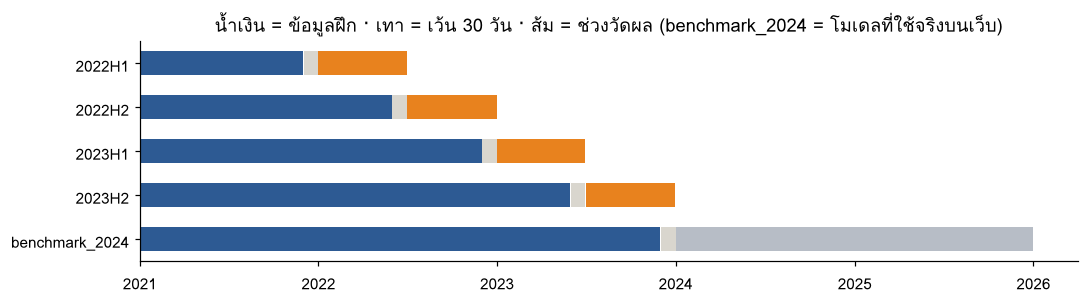

In [20]:
folds = pd.read_csv(RUN20 / "folds.csv")
f6 = folds[folds["unit"] == "6h"][["fold_id", "train_cutoff_local", "eval_start", "eval_end", "train_dates_per_block"]]
display(f6)

fig, ax = plt.subplots(figsize=(11, 2.6))
for i, r in enumerate(f6.itertuples()):
    t0, cut = pd.Timestamp("2021-01-01"), pd.Timestamp(r.train_cutoff_local)
    e0 = pd.Timestamp(r.eval_start); e1 = pd.Timestamp(r.eval_end) if isinstance(r.eval_end, str) and r.eval_end != "None" else pd.Timestamp("2025-12-31")
    ax.barh(i, (cut - t0).days, left=t0, color="#2D5A93", height=.55)
    ax.barh(i, (e0 - cut).days, left=cut, color="#D9D6CE", height=.55)
    ax.barh(i, (e1 - e0).days, left=e0, color="#E8821E" if r.fold_id != "benchmark_2024" else "#B7BDC6", height=.55)
ax.set_yticks(range(len(f6)), f6["fold_id"]); ax.invert_yaxis()
ax.set_title("น้ำเงิน = ข้อมูลฝึก · เทา = เว้น 30 วัน · ส้ม = ช่วงวัดผล (benchmark_2024 = โมเดลที่ใช้จริงบนเว็บ)")
plt.show()

ส่วนนี้ **เทรนใหม่จริง 1 รอบ** คือรอบ **2023H2** (ฝึกถึง 31 พ.ค. 2566 แล้ววัดผล ก.ค.–ธ.ค. 2566) หน่วย **ราย 6 ชั่วโมง** ด้วยโมเดลหลัก แล้วเทียบผลกับผลทางการของโน้ตบุ๊ก 20 ในส่วน F

### E2 · สุ่มแถวที่เป็น 0 (`sample_training` · โน้ตบุ๊ก 20 cell 3)

แถวฝึกของรอบนี้มี **26,740 × 881 วัน × 4 ช่วง ≈ 94 ล้านแถว** และเกือบทั้งหมดเป็น 0 ถ้าใช้ทั้งหมดจะช้าและใช้หน่วยความจำมาก จึง:
- เก็บ **ทุกแถวที่เกิดเหตุ** (น้ำหนัก = 1)
- ในแต่ละกลุ่ม (ช่วงถนน × ช่วงเวลา) สุ่มแถว 0 มา **ไม่เกิน 32 แถว** และให้ **น้ำหนัก = จำนวน 0 ทั้งหมด ÷ จำนวนที่สุ่ม**

> 💡 **ทำไมใส่น้ำหนัก:** ถ้าไม่ใส่ โมเดลจะเข้าใจว่าเกิดเหตุบ่อยกว่าความจริงหลายเท่า น้ำหนักทำให้ผลรวมของแถว 0 เท่ากับของจริง ผลรวมของน้ำหนัก (exposure) จึงเท่ากับ 94 ล้านแถวพอดี
>
> **การสุ่มใช้เฉพาะตอนฝึกโมเดล** ส่วน baseline และการวัดผลใช้ข้อมูลเต็มทุกช่อง

In [21]:
FOLD = "2023H2"
fr = folds[(folds["unit"] == "6h") & (folds["fold_id"] == FOLD)].iloc[0]
T = np.array(json.loads(fr["train_dates_per_block"]))          # จำนวนวันฝึกของแต่ละช่วง (ช่วง 18-24 จบหลังเวลาตัด จึงน้อยกว่า 1 วัน)
AX_DATES = pd.date_range("2021-01-01", "2025-12-31").strftime("%Y-%m-%d")
SEGS = np.sort(uni["segment_id"].to_numpy())                    # ลำดับช่วงถนนแบบเดียวกับ population_axes.json
seg_idx = pd.Series(np.arange(len(SEGS)), index=SEGS)
date_idx = pd.Series(np.arange(len(AX_DATES)), index=AX_DATES)

pos = pd.DataFrame({"d": date_idx.reindex(c6["target_date"]).to_numpy(), "s": seg_idx.reindex(c6["segment_id"]).to_numpy(),
                    "b": pd.Series(range(4), index=BLOCKS).reindex(c6["time_block"]).to_numpy(), "y": c6["y_count"].to_numpy()})
train_pos = pos[pos["d"] < T[pos["b"]]]                         # แถวเกิดเหตุที่อยู่ก่อนเวลาตัดของรอบนี้
print(f"วันฝึกต่อช่วง {T.tolist()} | แถวเกิดเหตุในช่วงฝึก {len(train_pos):,} แถว ({int(train_pos['y'].sum()):,} ครั้ง)")

K, SEED = EXP["sampling"]["max_zero_per_stratum"], EXP["sampling"]["seed"]
def stratum_seed(seg, block):
    # seed เฉพาะของแต่ละกลุ่ม → สุ่มซ้ำได้ผลเดิมเสมอ (เหมือนโน้ตบุ๊ก 20)
    return int(hashlib.sha256(f"{SEED}|6h|{FOLD}|{seg}|{block}".encode()).hexdigest()[:16], 16)

t0 = time.time()
tp = train_pos.sort_values(["s", "b", "d"])
grp = {k: g["d"].to_numpy() for k, g in tp.groupby(["s", "b"])}
D, S_, Bk, W = [], [], [], []
for s in range(len(SEGS)):
    for b in range(4):
        pdays = grp.get((s, b), np.empty(0, np.int64))
        nz = T[b] - len(pdays)
        m = min(K, nz)
        rng = np.random.default_rng(stratum_seed(SEGS[s], BLOCKS[b]))
        zd = np.setdiff1d(np.arange(T[b]), pdays, assume_unique=True)[np.sort(rng.choice(nz, m, replace=False))]
        D.append(zd); S_.append(np.full(m, s)); Bk.append(np.full(m, b)); W.append(np.full(m, nz / m))
zeros = pd.DataFrame({"d": np.concatenate(D), "s": np.concatenate(S_), "b": np.concatenate(Bk), "y": 0.0, "w": np.concatenate(W)})
sample = pd.concat([train_pos.assign(w=1.0, y=train_pos["y"].astype(float)), zeros], ignore_index=True).sort_values(["d", "s", "b"], kind="stable")
print(f"สุ่มเสร็จใน {time.time() - t0:.0f} วินาที → แถวฝึก {len(sample):,} แถว (เกิดเหตุ {len(train_pos):,} + ศูนย์ที่สุ่ม {len(zeros):,})")
print(f"ผลรวมน้ำหนัก = {sample['w'].sum():,.0f} (ควรเท่ากับช่องฝึกทั้งหมด {len(SEGS) * T.sum():,})")
display(pd.read_csv(RUN20 / "sampling.csv").query("unit == '6h' and fold_id == @FOLD")[["positive_cells", "zero_cells_sampled", "sample_rows", "weighted_exposure"]]
        .rename(index=lambda i: "ผลทางการ (โน้ตบุ๊ก 20)"))

วันฝึกต่อช่วง [881, 881, 881, 880] | แถวเกิดเหตุในช่วงฝึก 45,220 แถว (45,880 ครั้ง)
สุ่มเสร็จใน 7 วินาที → แถวฝึก 3,467,940 แถว (เกิดเหตุ 45,220 + ศูนย์ที่สุ่ม 3,422,720)
ผลรวมน้ำหนัก = 94,205,020 (ควรเท่ากับช่องฝึกทั้งหมด 94,205,020)


,positive_cells,zero_cells_sampled,sample_rows,weighted_exposure
ผลทางการ (โน้ตบุ๊ก 20),45220,3422720,3467940,94205020.0


### E3 · สร้างตาราง X (features) แล้วเทรน HistGradientBoosting

- **X** = ตัวแปรของถนน + ตัวแปรของวัน + ช่วงเวลา
- **y** = จำนวนอุบัติเหตุ, **w** = น้ำหนักจาก E2

ค่าตั้งของโมเดลมาจาก `config/spatial_experiment_v4.json` (`make_estimator` · โน้ตบุ๊ก 20 cell 5):

| พารามิเตอร์ | ค่า | ความหมาย |
|---|---|---|
| `loss` | `poisson` | เป้าหมายเป็นจำนวนนับ ผลที่ได้ไม่ติดลบ |
| `max_iter` | 160 | จำนวนต้นไม้ที่ต่อกัน (boosting rounds) |
| `learning_rate` | 0.05 | แต่ละต้นแก้ความผิดพลาดทีละน้อย |
| `max_leaf_nodes` | 15 | ต้นไม้เล็ก ลดการจำข้อมูล (overfit) |
| `min_samples_leaf` | 100 | ใบหนึ่งต้องมีอย่างน้อย 100 แถว |
| `l2_regularization` | 5.0 | ลงโทษค่าที่สุดโต่ง |
| `early_stopping` | False | จำนวนต้นคงที่ ผลซ้ำได้ |
| categorical | `route_code`, `time_block` | ใช้ `OrdinalEncoder` (เก็บ 255 สายที่พบบ่อย ที่เหลือรวมกลุ่ม) |

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

seg_static = uni.set_index("segment_id").loc[SEGS, STATIC[1:]].astype("float64").reset_index(drop=True)
seg_route = uni.set_index("segment_id").loc[SEGS, "route_code"].astype(str).to_numpy()
date_tab = dates.set_index("target_date").loc[AX_DATES, DATE_COLS].astype("float64").reset_index(drop=True)

def build_X(d, s, b):
    # ประกอบ X จากตำแหน่ง (วัน d, ช่วงถนน s, ช่วงเวลา b) ลำดับคอลัมน์ตาม FEATURES_6H
    X = pd.concat([pd.DataFrame({"route_code": seg_route[s]}), seg_static.iloc[s].reset_index(drop=True),
                   date_tab.iloc[d].reset_index(drop=True)], axis=1)
    X["time_block"] = np.asarray(BLOCKS, dtype=object)[b]
    return X[FEATURES_6H]

params = next(c for c in EXP["candidates"]["configs"] if c["config_id"] == "hgb_poisson_fixed")["params"]
CATS = ["route_code", "time_block"]
NUMS = [c for c in FEATURES_6H if c not in CATS]
model = Pipeline([
    ("pre", ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan,
                                                      max_categories=255, dtype=np.float64), CATS),
                               ("num", "passthrough", NUMS)], remainder="drop", sparse_threshold=0.0)),
    ("model", HistGradientBoostingRegressor(categorical_features=[True] * len(CATS) + [False] * len(NUMS), **params)),
])
print("พารามิเตอร์:", params)

Xtr = build_X(sample["d"].to_numpy(), sample["s"].to_numpy(), sample["b"].to_numpy())
print("ขนาด X สำหรับฝึก:", Xtr.shape)
display(Xtr.head(3))

t0 = time.time()
model.fit(Xtr, sample["y"].to_numpy(), model__sample_weight=sample["w"].to_numpy())
print(f"เทรนเสร็จใน {time.time() - t0:.0f} วินาที")
del Xtr

พารามิเตอร์: {'loss': 'poisson', 'max_iter': 160, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'l2_regularization': 5.0, 'learning_rate': 0.05, 'early_stopping': False, 'max_bins': 255, 'random_state': 42}
ขนาด X สำหรับฝึก: (3467940, 34)
เทรนเสร็จใน 86 วินาที


,route_code,geom_mid_x_m,geom_mid_y_m,geom_mid_lon,geom_mid_lat,geom_length_m,geom_log_length_m,geom_bearing_sin,geom_bearing_cos,geom_straightness,geom_turning_rad_per_km,day_of_week,month,day_of_month,is_weekend,doy_sin,doy_cos,fest_songkran_dist,fest_songkran_in,fest_songkran_pre_1_3,fest_songkran_pre_4_7,fest_songkran_post_1_3,fest_songkran_post_4_7,fest_new_year_dist,fest_new_year_in,fest_new_year_pre_1_3,fest_new_year_pre_4_7,fest_new_year_post_1_3,fest_new_year_post_4_7,season_hot,season_wet,season_cool,bank_holiday_asof,time_block
0,3420,665369.160728,1.710763e+06,100.541460,15.468724,2000.0,7.600902,0.944948,-0.327222,0.999935,0.475720,4.0,1.0,1.0,0.0,0.0,1.0,-14.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,00-06
1,1087,488405.866393,1.958431e+06,98.890655,17.712952,2000.0,7.600902,-0.964186,-0.265228,0.949501,1.557958,4.0,1.0,1.0,0.0,0.0,1.0,-14.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,18-24
2,1087,486202.314654,1.953131e+06,98.869908,17.665026,2000.0,7.600902,0.502068,-0.864828,0.859075,4.954510,4.0,1.0,1.0,0.0,0.0,1.0,-14.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,NaN,06-12


### E4 · Baseline: วิธีสถิติง่าย ๆ ที่โมเดลต้องชนะ (`fit_baselines` · โน้ตบุ๊ก 20 cell 4)

Baseline ที่แข็งที่สุดคือ **`segment_mean_k365`**:

$$\hat y_{s,b} = \frac{C_{s,b} + k \cdot P_{s,b}}{N_{b} + k},\quad k = 365$$

- $C_{s,b}$ = จำนวนเหตุของช่วงถนน s ช่วงเวลา b ในช่วงฝึก
- $N_b$ = จำนวนวันฝึก
- $P_{s,b}$ = อัตราเฉลี่ยของ **ทั้งสายทาง** ต่อ กม. × ความยาวช่วงถนน

> 💡 ช่วงถนน 2 กม. ส่วนใหญ่แทบไม่เคยเกิดเหตุ ถ้าใช้ค่าเฉลี่ยของช่วงนั้นเพียงอย่างเดียว ค่าจะแกว่งมาก จึง "ดึง" เข้าหาค่าของทั้งสายทาง เหมือนเติมข้อมูลสมมติ 365 วันของสายทางนั้นเข้าไป (shrinkage)

baseline นี้คำนวณจาก **ข้อมูลฝึกเต็มทุกช่อง** ไม่ได้ใช้ข้อมูลที่สุ่มมา

In [23]:
km = uni.set_index("segment_id").loc[SEGS, "geom_length_m"].to_numpy() / 1000
C = np.zeros((len(SEGS), 4)); np.add.at(C, (train_pos["s"].to_numpy(), train_pos["b"].to_numpy()), train_pos["y"].to_numpy())
routes, ri = np.unique(seg_route, return_inverse=True)
Cr = np.zeros((len(routes), 4)); np.add.at(Cr, ri, C)
Lr = np.bincount(ri, weights=km)
P = (Cr / (Lr[:, None] * T[None, :]))[ri] * km[:, None]        # อัตราของสายทางต่อ กม. × ความยาวช่วง
k = 365
BASE = (C + k * P) / (T[None, :] + k)                            # ค่าทำนายของ baseline (ช่วงถนน × ช่วงเวลา) คงที่ทุกวัน
print("ตัวอย่างค่าทำนายของ baseline (ครั้ง / ช่วงถนน / 6 ชม.):")
display(pd.DataFrame(BASE[:3], columns=BLOCKS, index=SEGS[:3]))

ตัวอย่างค่าทำนายของ baseline (ครั้ง / ช่วงถนน / 6 ชม.):


,00-06,06-12,12-18,18-24
rsv1-rc315c7c508f:doh:1000:p0:c0:r2000:00000,0.0,0.0,0.0,0.0
rsv1-rc315c7c508f:doh:1000:p0:c0:r2000:00001,0.0,0.0,0.0,0.0
rsv1-rc315c7c508f:doh:1001:p0:c0:r2000:00000,0.0,0.0,0.0,0.0


---
# ส่วน F · วัดผล

### F1 · ตัวชี้วัด: Poisson deviance (`poisson_deviance_terms` · โน้ตบุ๊ก 20 cell 6)

$$\text{deviance}(y, \mu) = 2\left(y \log\frac{y}{\mu} - (y - \mu)\right) \qquad (\text{ถ้า } y = 0:\ 2\mu)$$

- ยิ่ง **ต่ำยิ่งดี** และเป็นตัวชี้วัดหลักในการเลือกโมเดล
- ลงโทษหนักเมื่อเกิดเหตุจริงแต่โมเดลทายต่ำมาก และลงโทษเบาเมื่อทายค่าเล็ก ๆ ในช่องที่ไม่เกิดเหตุ
- ดูประกอบกับ **MAE** (ค่าความคลาดเคลื่อนสัมบูรณ์เฉลี่ย)

ตัวอย่างการคำนวณ:

In [24]:
def poisson_deviance(y, mu, floor=1e-12):
    y, mu = np.asarray(y, float), np.maximum(np.asarray(mu, float), floor)
    ylog = np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0.0)
    return 2 * (ylog - (y - mu))

ex = pd.DataFrame({"y จริง": [0, 0, 1, 1], "ค่าที่ทาย μ": [0.001, 0.1, 0.001, 0.5]})
ex["deviance"] = poisson_deviance(ex["y จริง"], ex["ค่าที่ทาย μ"]).round(4)
display(ex)
print("→ เกิดเหตุจริง (y=1) แต่ทายแค่ 0.001 จะโดนลงโทษหนักที่สุด")

→ เกิดเหตุจริง (y=1) แต่ทายแค่ 0.001 จะโดนลงโทษหนักที่สุด


,y จริง,ค่าที่ทาย μ,deviance
0,0,0.001,0.0020
1,0,0.100,0.2000
2,1,0.001,11.8175
3,1,0.500,0.3863


### F2 · วัดผลรอบ 2023H2 ด้วยข้อมูลเต็ม 19.7 ล้านช่อง

ทำนาย **ทุกช่วงถนน × ทุกวัน (ก.ค.–ธ.ค. 2566) × 4 ช่วงเวลา** รวมช่องที่ไม่เกิดเหตุด้วย ทำทีละ 7 วันเพื่อไม่ให้หน่วยความจำเต็ม (ใช้เวลาสักครู่)

In [25]:
e0, e1 = date_idx["2023-07-01"], date_idx["2023-12-31"]
ev_pos = pos[(pos["d"] >= e0) & (pos["d"] <= e1)]
ymap = {(d, s, b): y for d, s, b, y in ev_pos[["d", "s", "b", "y"]].itertuples(index=False)}
S, nS = np.arange(len(SEGS)), len(SEGS)
acc = {"hgb": [0.0, 0.0], "base": [0.0, 0.0]}
pred_sum = {"hgb": 0.0, "base": 0.0}
by_block = np.zeros((2, 4)); n_block = np.zeros(4)
mu_hgb_days = []      # เก็บค่าทำนายไว้คำนวณสีในส่วน F5
t0 = time.time()
for d0 in range(e0, e1 + 1, 7):
    dd = np.arange(d0, min(d0 + 7, e1 + 1))
    d = np.repeat(dd, nS * 4); s = np.tile(np.repeat(S, 4), len(dd)); b = np.tile(np.arange(4), nS * len(dd))
    mu = model.predict(build_X(d, s, b))
    mb = BASE[s, b]
    y = np.zeros(len(d))
    hit = ev_pos[(ev_pos["d"] >= dd[0]) & (ev_pos["d"] <= dd[-1])]
    if len(hit):
        idx = (hit["d"].to_numpy() - dd[0]) * nS * 4 + hit["s"].to_numpy() * 4 + hit["b"].to_numpy()
        y[idx] = hit["y"].to_numpy()
    for name, m_ in (("hgb", mu), ("base", mb)):
        acc[name][0] += poisson_deviance(y, m_).sum(); acc[name][1] += np.abs(y - m_).sum(); pred_sum[name] += m_.sum()
    for bi in range(4):
        sel_b = b == bi
        by_block[0, bi] += poisson_deviance(y[sel_b], mu[sel_b]).sum(); by_block[1, bi] += poisson_deviance(y[sel_b], mb[sel_b]).sum(); n_block[bi] += sel_b.sum()
    mu_hgb_days.append(mu.astype(np.float32))
N = (e1 - e0 + 1) * nS * 4
print(f"ทำนายครบ {N:,} ช่องใน {time.time() - t0:.0f} วินาที | เกิดเหตุจริง {int(ev_pos['y'].sum()):,} ครั้ง")

res = pd.DataFrame({"วิธี": ["HGB (โมเดลหลัก, เทรนในโน้ตบุ๊กนี้)", "Baseline segment_mean_k365"],
                    "mean Poisson deviance": [acc["hgb"][0] / N, acc["base"][0] / N],
                    "MAE": [acc["hgb"][1] / N, acc["base"][1] / N],
                    "ผลรวมที่ทาย / ที่เกิดจริง": [pred_sum["hgb"] / ev_pos["y"].sum(), pred_sum["base"] / ev_pos["y"].sum()]})
display(res)
gain = 1 - res.iloc[0, 1] / res.iloc[1, 1]
print(f"→ HGB มี deviance ต่ำกว่า baseline {gain:.1%}")

ทำนายครบ 19,680,640 ช่องใน 153 วินาที | เกิดเหตุจริง 9,171 ครั้ง
→ HGB มี deviance ต่ำกว่า baseline 4.5%


,วิธี,mean Poisson deviance,MAE,ผลรวมที่ทาย / ที่เกิดจริง
0,"HGB (โมเดลหลัก, เทรนในโน้ตบุ๊กนี้)",0.006286,0.000897,0.932661
1,Baseline segment_mean_k365,0.006583,0.000949,1.045124


**เทียบกับผลทางการของโน้ตบุ๊ก 20** (รอบเดียวกัน หน่วยเดียวกัน) ตัวเลขควรใกล้เคียงกันมาก ที่ไม่เท่ากันพอดีเพราะลำดับแถวและการแบ่งช่วงค่า (binning) ภายใน HGB ต่างกันเล็กน้อย

In [26]:
fm = pd.read_csv(RUN20 / "fold_metrics.csv")
off = fm[(fm["unit"] == "6h") & (fm["fold_id"] == FOLD) & fm["method"].isin(["hgb_poisson_fixed::core", "segment_mean_k365"])][["method", "mean_poisson_deviance", "mae", "pred_over_actual"]]
off = off.rename(columns={"method": "วิธี (ผลทางการ)", "pred_over_actual": "ผลรวมที่ทาย / ที่เกิดจริง"})
display(off)
o = off.set_index("วิธี (ผลทางการ)")["mean_poisson_deviance"]
print(f"ผลทางการ: HGB ดีกว่า baseline {1 - o['hgb_poisson_fixed::core'] / o['segment_mean_k365']:.1%} | ในโน้ตบุ๊กนี้: {gain:.1%}")

ผลทางการ: HGB ดีกว่า baseline 4.6% | ในโน้ตบุ๊กนี้: 4.5%


,วิธี (ผลทางการ),mean_poisson_deviance,mae,ผลรวมที่ทาย / ที่เกิดจริง
55,hgb_poisson_fixed::core,0.006283,0.000898,0.933331
91,segment_mean_k365,0.006583,0.000949,1.045124


### F3 · ผลทั้ง 4 รอบ และเกณฑ์เลือกโมเดล (`select_unit` · โน้ตบุ๊ก 20 cell 6)

เกณฑ์ถูก **ล็อกไว้ก่อนดูผล** (`selection` ใน config):
1. deviance รวมทั้ง 4 รอบลดลงจาก baseline ที่ดีที่สุด **อย่างน้อย 1%**
2. MAE แย่ลงได้ **ไม่เกิน 2%** (อัตราส่วน ≤ 1.02)
3. ต้องชนะ baseline **อย่างน้อย 3 ใน 4 รอบ**

ถ้าไม่ผ่านทุกข้อ ระบบจะใช้ baseline แทน

เซลล์ด้านล่างคำนวณเกณฑ์ใหม่จากผลทางการทั้ง 4 รอบ:

,หน่วย,baseline ที่ดีที่สุด,ลด deviance,ผ่าน ≥1%,อัตราส่วน MAE,ผ่าน ≤1.02,ชนะ (รอบ),ผ่าน ≥3/4
0,daily,segment_mean_k365,2.65%,True,0.9964,True,3/4,True
1,6h,segment_mean_k365,10.62%,True,0.9975,True,4/4,True


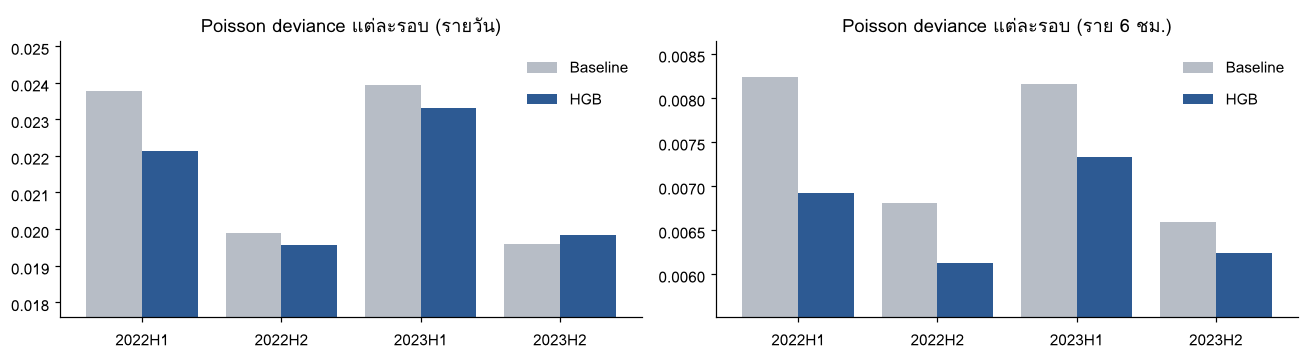

In [27]:
SELM = "hgb_poisson_fixed::routed_context"   # นโยบายที่ใช้จริง (มีบริบทใช้บริบท ไม่มีใช้โมเดลหลัก)
rows = []
for unit in ["daily", "6h"]:
    f = fm[(fm["unit"] == unit) & fm["fold_id"].isin(["2022H1", "2022H2", "2023H1", "2023H2"])]
    pooled = f.groupby("method").apply(lambda g: pd.Series({"dev": (g["mean_poisson_deviance"] * g["n"]).sum() / g["n"].sum(),
                                                             "mae": (g["mae"] * g["n"]).sum() / g["n"].sum()}))
    bases = [m for m in pooled.index if "::" not in m and m != "zero"]
    best_base = pooled.loc[bases, "dev"].idxmin()
    red = 1 - pooled.loc[SELM, "dev"] / pooled.loc[best_base, "dev"]
    ratio = pooled.loc[SELM, "mae"] / pooled.loc[best_base, "mae"]
    per = f.pivot(index="fold_id", columns="method", values="mean_poisson_deviance")
    wins = int((per[SELM] < per[best_base]).sum())
    rows.append({"หน่วย": unit, "baseline ที่ดีที่สุด": best_base, "ลด deviance": f"{red:.2%}", "ผ่าน ≥1%": red >= .01,
                 "อัตราส่วน MAE": round(ratio, 4), "ผ่าน ≤1.02": ratio <= 1.02, "ชนะ (รอบ)": f"{wins}/4", "ผ่าน ≥3/4": wins >= 3})
gates = pd.DataFrame(rows)
display(gates)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for a, unit in zip(ax, ["daily", "6h"]):
    p = fm[(fm["unit"] == unit) & fm["fold_id"].isin(["2022H1", "2022H2", "2023H1", "2023H2"])].pivot(index="fold_id", columns="method", values="mean_poisson_deviance")
    x = np.arange(len(p))
    a.bar(x - .2, p["segment_mean_k365"], .4, color="#B7BDC6", label="Baseline")
    a.bar(x + .2, p[SELM], .4, color="#2D5A93", label="HGB")
    a.set_xticks(x, p.index); a.set_title(f"Poisson deviance แต่ละรอบ ({'รายวัน' if unit == 'daily' else 'ราย 6 ชม.'})"); a.legend(frameon=False)
    a.set_ylim(p[[SELM, "segment_mean_k365"]].min().min() * .9, None)
plt.tight_layout(); plt.show()

> 💡 **อ่านผล:** หน่วย **ราย 6 ชม.** ชนะชัดทั้ง 4 รอบ ส่วน **รายวัน** ผ่านเกณฑ์แบบเฉียด ๆ เว็บจึงใช้หน่วยราย 6 ชม. ซึ่งรู้ได้ด้วยว่าเสี่ยงช่วงเวลาไหนของวัน

**ทำไม HGB:** รอบนำร่อง (โน้ตบุ๊ก `25_model_gate_summary_th` ช่วงถนน 3,105 ช่วง) เทียบ **Poisson Regression (GLM)**, **Random Forest (Poisson)** และ **HGB (Poisson)** แล้ว HGB ดีที่สุด จึงนำ HGB ไปรันกับทั้งประเทศ

### F4 · Error analysis: ช่วงเวลาไหนทำนายยาก

In [28]:
eb = pd.DataFrame({"ช่วงเวลา": BLOCKS, "HGB": by_block[0] / n_block, "Baseline": by_block[1] / n_block})
eb["HGB ดีกว่า"] = (1 - eb["HGB"] / eb["Baseline"]).map("{:.1%}".format)
display(eb)

sm = pd.read_csv(RUN20 / "strata_metrics.csv")
for stratum, label in [("festival_window", "ช่วงเทศกาล (yes = สงกรานต์/ปีใหม่ ±7 วัน)"), ("season", "ฤดู"), ("time_block", "ช่วงเวลา")]:
    t = sm[(sm["unit"] == "6h") & (sm["scope"] == "oof_2022_2023") & (sm["stratum"] == stratum) & sm["method"].isin([SELM, "segment_mean_k365"])]
    t = t.pivot_table(index="level", columns="method", values="mean_poisson_deviance", aggfunc="mean")
    t["HGB ดีกว่า"] = (1 - t[SELM] / t["segment_mean_k365"]).map("{:.1%}".format)
    print("ผลทางการ (OOF 2565–2566, ราย 6 ชม.) แยกตาม", label); display(t)

ผลทางการ (OOF 2565–2566, ราย 6 ชม.) แยกตาม ช่วงเทศกาล (yes = สงกรานต์/ปีใหม่ ±7 วัน)
ผลทางการ (OOF 2565–2566, ราย 6 ชม.) แยกตาม ฤดู
ผลทางการ (OOF 2565–2566, ราย 6 ชม.) แยกตาม ช่วงเวลา


,ช่วงเวลา,HGB,Baseline,HGB ดีกว่า
0,00-06,0.005501,0.005901,6.8%
1,06-12,0.006668,0.006974,4.4%
2,12-18,0.007115,0.007403,3.9%
3,18-24,0.005859,0.006052,3.2%


method,hgb_poisson_fixed::routed_context,segment_mean_k365,HGB ดีกว่า
level,,,
no,0.006141,0.006697,8.3%
yes,0.011757,0.014894,21.1%


method,hgb_poisson_fixed::routed_context,segment_mean_k365,HGB ดีกว่า
level,,,
cool,0.006954,0.007903,12.0%
hot,0.007259,0.008390,13.5%
wet,0.006043,0.006502,7.1%


method,hgb_poisson_fixed::routed_context,segment_mean_k365,HGB ดีกว่า
level,,,
0,0.005405,0.006134,11.9%
1,0.007023,0.007832,10.3%
2,0.007895,0.008734,9.6%
3,0.006272,0.007053,11.1%


### F5 · จากค่าทำนายเป็น "สี" บนแผนที่ (`build_colour_contract` · โน้ตบุ๊ก 21 cell 4)

1. แปลงค่าทำนายเป็น **ความหนาแน่น = จำนวนที่คาดว่าจะเกิด ÷ ความยาว (กม.)** เพื่อให้ช่วงสั้นและยาวเทียบกันได้
2. หาเปอร์เซ็นไทล์ของความหนาแน่นทั้งประเทศ
   - **ส้ม (สูง)** = เกินเปอร์เซ็นไทล์ 80 (20% บนสุด)
   - **แดง (สูงมาก)** = เกินเปอร์เซ็นไทล์ 95 (5% บนสุด)
3. จุดตัดนี้ **คงที่ทั้งประเทศ** สีแดงบนถนนสายไหนก็มีความหมายเดียวกัน

> 💡 สีเป็นการ **เทียบกับถนนเส้นอื่น** ไม่ใช่โอกาสที่คนขับคนหนึ่งจะเกิดอุบัติเหตุ

In [29]:
mu_all = np.concatenate(mu_hgb_days)
km_rows = np.tile(np.repeat(km, 4), len(mu_all) // (nS * 4))
dens = mu_all / km_rows
q80, q95 = np.quantile(dens, [.80, .95])
cc = json.loads((RUN21 / "colour_contract_6h.json").read_text("utf-8"))
display(pd.DataFrame({"จุดตัด": ["ส้ม (P80)", "แดง (P95)"],
                      "จากโน้ตบุ๊กนี้ (2023H2)": [q80, q95],
                      "ผลทางการ (OOF 2565–2566 ทั้งหมด)": cc["raw_cutoffs"][1:3]}))
print("หน่วย: ครั้ง ต่อ กม. ต่อ 6 ชม.")
del mu_all, km_rows, dens

หน่วย: ครั้ง ต่อ กม. ต่อ 6 ชม.


,จุดตัด,จากโน้ตบุ๊กนี้ (2023H2),ผลทางการ (OOF 2565–2566 ทั้งหมด)
0,ส้ม (P80),0.000269,0.000309
1,แดง (P95),0.000679,0.000770


### F6 · ผลกับปี 2567–2568 (ช่วงตรวจ)

โมเดลที่ใช้จริงบนเว็บคือรอบ **`benchmark_2024`** ฝึกด้วยข้อมูลถึง **1 ธ.ค. 2566** แล้ว **ล็อกไว้ ไม่ฝึกใหม่**

ปี 2567–2568 ทีมเคยเห็นผลระหว่างพัฒนาแล้ว จึงเรียกว่าช่วง "ตรวจ" ไม่ใช่ชุดทดสอบ

In [30]:
dg = pd.read_csv(RUN20 / "diagnostics_seen_2024_2025.csv")
t = dg.pivot_table(index=["unit", "year"], columns="role", values="mean_poisson_deviance")
t["HGB ดีกว่า"] = (1 - t["selected"] / t["strongest_baseline"]).map("{:.1%}".format)
display(t)

role             selected  strongest_baseline HGB ดีกว่า
unit  year                                              
6h    seen_2024  0.006731            0.007307       7.9%
      seen_2025  0.007348            0.008076       9.0%
daily seen_2024  0.021461            0.021660       0.9%
      seen_2025  0.023467            0.024000       2.2%

### F7 · ทดสอบจริงกับปี 2569 (โน้ตบุ๊ก 23)

ปี 2569 (ม.ค.–ก.ย.) เป็นข้อมูลที่ **โมเดลไม่เคยเห็น และทีมไม่เคยใช้ปรับอะไรเลย** จึงเป็นการทดสอบที่ตรงที่สุด

- ข้อมูลปี 2569 ผ่านการทำความสะอาดและจับคู่ถนนแบบเดียวกับส่วน B–C (เหลือ **15,425** รายการ จากไฟล์ล่าสุด 18,448 แถว)
- ทำนายด้วยโมเดลที่ล็อกไว้ แล้วเทียบกับ baseline

> ⚠️ **วิธีวัดของปี 2569 ต่างจากรอบก่อน:** ข้อมูลปี 2569 ยังรู้ไม่ครบว่าช่องไหน "ไม่เกิดเหตุจริง" (อาจถูกบันทึกเพิ่มภายหลัง) โน้ตบุ๊ก 23 จึงวัดเฉพาะ **ช่องที่มีอุบัติเหตุเกิดขึ้นจริง** และถามว่า **โมเดลให้ค่าคาดการณ์กับจุดที่เกิดเหตุจริงได้ดีกว่า baseline แค่ไหน** (deviance ยิ่งต่ำยิ่งดี) ช่องที่ไม่รู้ผลไม่ถูกนับเป็นศูนย์

ภาพรวมปี 2569 (ม.ค.–ก.ย.)
ช่วงเทศกาล
HGB ดีกว่าทุกเดือน: True


,unit,group,ช่องที่เกิดเหตุ,deviance HGB,deviance baseline,HGB ดีกว่า
0,daily,all,15011,9.262852,9.903833,6.5%
1038,6h,all,15202,11.843458,13.686493,13.5%


,unit,group,ช่องที่เกิดเหตุ,deviance HGB,deviance baseline,HGB ดีกว่า
61,daily,new_year_2026,685,7.887478,11.012718,28.4%
62,daily,none,13331,9.405109,9.768200,3.7%
63,daily,songkran_2026,995,8.303768,10.957648,24.2%
1102,6h,new_year_2026,700,10.383112,15.358768,32.4%
1103,6h,none,13492,11.988004,13.475607,11.0%
1104,6h,songkran_2026,1010,10.924678,15.344594,28.8%


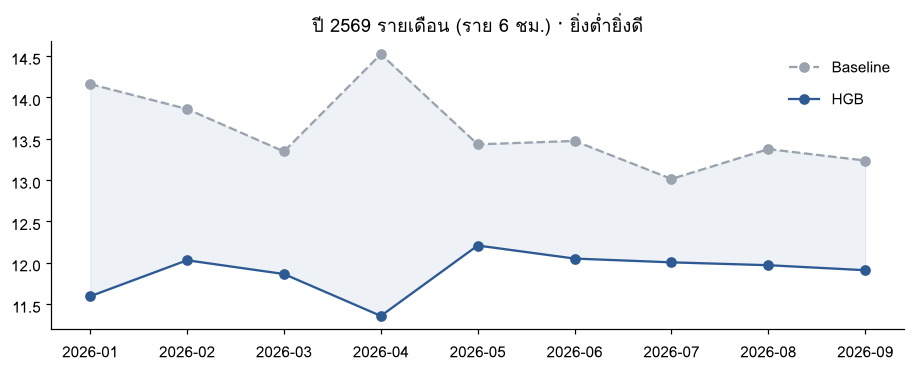

In [31]:
mc = pd.read_csv(RUN23 / "method_comparison.csv")
def table(dim):
    t = mc[mc["dim"] == dim][["unit", "group", "n_positive_cells", "deviance_floor_audit_selected", "deviance_floor_audit_baseline"]].copy()
    t["HGB ดีกว่า"] = (1 - t["deviance_floor_audit_selected"] / t["deviance_floor_audit_baseline"]).map("{:.1%}".format)
    return t.rename(columns={"n_positive_cells": "ช่องที่เกิดเหตุ", "deviance_floor_audit_selected": "deviance HGB", "deviance_floor_audit_baseline": "deviance baseline"})
print("ภาพรวมปี 2569 (ม.ค.–ก.ย.)"); display(table("overall"))
print("ช่วงเทศกาล"); display(table("festival"))

m6 = mc[(mc["dim"] == "month") & (mc["unit"] == "6h")].sort_values("group")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(m6["group"], m6["deviance_floor_audit_baseline"], "--o", color="#9AA3AE", label="Baseline")
ax.plot(m6["group"], m6["deviance_floor_audit_selected"], "-o", color="#2D5A93", label="HGB")
ax.fill_between(m6["group"], m6["deviance_floor_audit_selected"], m6["deviance_floor_audit_baseline"], color="#2D5A93", alpha=.08)
ax.set_title("ปี 2569 รายเดือน (ราย 6 ชม.) · ยิ่งต่ำยิ่งดี"); ax.legend(frameon=False)
plt.show()
print("HGB ดีกว่าทุกเดือน:", bool((m6["deviance_floor_audit_selected"] < m6["deviance_floor_audit_baseline"]).all()))

---
# สรุป

| ขั้น | ผลลัพธ์ |
|---|---|
| ข้อมูลดิบ 2564–2568 | **112,136** รายการ |
| หลังทำความสะอาด | **106,308** รายการ (ตัดพิกัดใช้ไม่ได้ รหัสซ้ำที่ข้อมูลขัดกัน และไม่มีจังหวัด) |
| จับคู่ถนนภายใน 50 ม. + อยู่ในชุดถนน | **98,207** รายการ บน 26,740 ช่วงถนน (51,858 กม.) |
| ตารางที่โมเดลทำนาย | 195 ล้านช่อง (ช่วงถนน × วัน × ช่วง 6 ชม.) มากกว่า 99.9% เป็น 0 |
| โมเดล | HistGradientBoosting, loss = Poisson, ฝึกด้วยแถวเกิดเหตุทุกแถว + แถว 0 ที่สุ่มพร้อมน้ำหนัก |
| วัดผลย้อนหลัง 4 รอบ (ราย 6 ชม.) | deviance ต่ำกว่า baseline ~10.6% ชนะ 4/4 รอบ |
| ทดสอบปี 2569 (ราย 6 ชม., วัดที่ช่องเกิดเหตุจริง) | deviance ต่ำกว่า baseline ~13.5% ดีกว่าทุกเดือน |

**ข้อจำกัดที่ควรพูดตรง ๆ:**
- นับเฉพาะอุบัติเหตุที่ **ถูกบันทึก** และจับคู่ถนนได้ ไม่ใช่ทุกเหตุที่เกิดจริง
- ครอบคลุมเฉพาะทางหลวงกรมทางหลวง
- ปี 2567 ขึ้นไปไม่มีข้อมูลอากาศ โมเดลบนเว็บจึงใช้ถนน + ปฏิทินเป็นหลัก
- สีบนแผนที่เป็นการจัดอันดับเทียบกับถนนอื่น ไม่ใช่ความน่าจะเป็นที่จะเกิดเหตุกับคนขับ